In [1]:
import argparse
import sys
import contextlib
import gc
import logging
import os
import time
import traceback
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
from flwr.simulation import run_simulation
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.metrics import auc as sk_auc
 
import config
import fl_basic6 as fl            # <- modul strategy/client (fedavg, fedprox, fedpairwise varian)
from dataset import DROP_COLS, TARGET
 
# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
 
# Varian fedpairwise diambil dari modul FL (fl.PW_VARIANTS):
#   fedpairwise_T0.01_d0.3, fedpairwise_T0.01_d0.5, fedpairwise_T0.01_d0
PW_VARIANTS = dict(getattr(fl, 'PW_VARIANTS', {}))
PW_NAMES = list(PW_VARIANTS)
 
ALGOS = ['fedavg', 'fedprox', *PW_NAMES]
BASELINE = 'fedavg'                      # pembanding untuk uji berpasangan
ORIG_OUT_DIR = Path(config.OUT_DIR)      # folder induk output = ORIG_OUT_DIR.parent
ORIG_SEED = int(config.SEED)
 
SEEDS = [42, 0, 123, 1337, 3407]
 
# Batas paralelisme Ray: jumlah client yang jalan bersamaan.
# Tiap actor memuat datanya sendiri, jadi nilai besar = RAM cepat habis -> node Ray mati.
# Turunkan (mis. 2) bila error "actor died / node has died" masih muncul.
MAX_PARALLEL = 4
 
# State untuk TRAINING. EVALUASI (val & test) tetap memakai SEMUA client.
TOP10_STATES = [13, 54, 41, 5, 10, 39, 23, 33, 19, 29]
TOP20_STATES = [4, 5, 10, 12, 13, 19, 22, 23, 29, 30,
                33, 34, 37, 39, 41, 48, 50, 53, 54, 55]   # superset dari TOP10
STATE_SETS = {'top10': TOP10_STATES, 'top20': TOP20_STATES}
DEFAULT_SET = 'top20'         # 'top10' | 'top20' | None (= semua state)
                              # bisa ditimpa lewat --top10 / --top20 / --all / --states
 
# Metrik dari fl_basic6: acc, prec, rec, f1, auc, prauc (prauc = Average Precision)
METRIK = list(fl.METRIK)
TEST_COLS = METRIK                                   # test pooled (semua client)
VAL_COLS = [f'val_{k}' for k in METRIK]              # val pooled (semua client, model akhir)
GRUP_COLS = [f'{m}_{g}' for g in ('latih', 'non_latih')
             for m in ('f1', 'auc', 'prauc')]        # test pooled per grup client
EXTRA_COLS = ['f1_macro_klien', 'f1_std_klien', 'val_f1_macro_klien',
              'val_f1_akhir', 'val_f1_terbaik', 'prauc_trapz',
              'n_client_eval', *GRUP_COLS, 'total_MB', 'waktu_s']
ALL_COLS = TEST_COLS + VAL_COLS + EXTRA_COLS
PAIRED_METRICS = ('f1', 'auc', 'prauc')
 
# ---- logging ----
VERBOSE = False                          # True = semua print tampil di konsol
LOG_DIR = ORIG_OUT_DIR.parent
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_FLWR = LOG_DIR / 'flwr.log'
LOG_PRINTS = LOG_DIR / 'prints.log'
 
 
def setup_flwr_logging():
    """Console Flower hanya WARNING+; detail penuh ke file. Aman dipanggil berulang."""
    lg = logging.getLogger("flwr")
    for h in lg.handlers:
        if not isinstance(h, logging.FileHandler):
            h.setLevel(logging.WARNING)
    if not any(isinstance(h, logging.FileHandler) for h in lg.handlers):
        fh = logging.FileHandler(LOG_FLWR, encoding="utf-8")
        fh.setLevel(logging.INFO)
        fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
        lg.addHandler(fh)
    lg.setLevel(logging.INFO)
 
 
@contextlib.contextmanager
def quiet(logfile=None):
    """Alihkan print() ke file. Dinonaktifkan bila VERBOSE."""
    if VERBOSE:
        yield
        return
    with open(logfile or LOG_PRINTS, "a", encoding="utf-8") as f, \
            contextlib.redirect_stdout(f):
        yield
 
 
setup_flwr_logging()

c:\Users\s2\Documents\FIXRKI\.fed\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-29 15:42:33,302	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:
# ============================================================
# 1. DATASET, MODUL & RINGKASAN DATA
# ============================================================
def setup_dataset():
    """Arahkan config ke folder dataset dan buang cache data lama."""
    if not CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {CLIENT_DIR}")
    config.CLIENT_DIR = CLIENT_DIR
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)
    try:
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    fl.clear_cache()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")
 
 
def apply_states(states):
    """Batasi client TRAINING ke daftar state tertentu (None = semua state).
    Evaluasi tetap memakai semua client.
    Harus dipanggil SEBELUM simulasi agar worker Ray ikut mewarisi env var."""
    if states:
        os.environ['FL_STATES'] = ','.join(str(s) for s in states)
    else:
        os.environ.pop('FL_STATES', None)
    fl.clear_cache()
    print(f"Filter state (training): {list(states) if states else 'semua state'}")
 
 
def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    print(f"Metrik  : {METRIK}")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")
        if PW_VARIANTS:
            print("Varian pairwise (temperature, data_influence):")
            for nama, (t, d) in PW_VARIANTS.items():
                print(f"  - {nama}: T={t}, data_influence={d}")
        else:
            print("[peringatan] fl.PW_VARIANTS tidak ditemukan; "
                  "pastikan fl_basic6 adalah versi terbaru")
    else:
        print("Agregasi pairwise: TIDAK tersedia (aggregation4 gagal diimpor)")
 
 
def available_algos(algos):
    known = set(getattr(fl, 'ALGOS', algos))
    ok, skip = [], []
    for a in algos:
        if a not in known:
            skip.append(a)
        elif a in PW_VARIANTS and getattr(fl, 'FedCosinePairwise', None) is None:
            skip.append(a)
        else:
            ok.append(a)
    if skip:
        print(f"[lewati] tidak tersedia di {fl.__name__}: {skip}")
    return ok
 
 
def data_summary():
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
    print("=" * 50)
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    for i, nama in enumerate(feature_names, 1):
        print(f"{i:>3}. {nama}")
 
    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}
 
    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total
 
    print("\nRingkasan per client (TRAINING):")
    print(ringkas.to_string())
 
    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
 
    # ---- ringkasan client EVALUASI (semua client) ----
    eval_clients = fl.load_eval_clients()
    non_latih = [s for s in eval_clients if s not in clients]
    print("\n" + "=" * 50)
    print(f"Client TRAINING   : {len(clients)} -> {list(clients)}")
    print(f"Client EVALUASI   : {len(eval_clients)} (val & test semua client)")
    print(f"Tidak ikut latih  : {len(non_latih)} -> {non_latih}")
    n_val_all = sum(len(c['y_val_t']) for c in eval_clients.values())
    n_test_all = sum(len(c['y_test_t']) for c in eval_clients.values())
    print(f"Total sampel eval : val={n_val_all:,} | test={n_test_all:,}")
    print("=" * 50)
 
    return n_clients          # = jumlah client TRAINING (dipakai num_supernodes)

In [3]:

# %%
# ============================================================
# 2. JALANKAN SATU (ALGORITMA, SEED)
# ============================================================
def _shutdown_ray():
    """Matikan Ray (bila aktif) dan bebaskan memori antar run."""
    try:
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    gc.collect()
    time.sleep(2)                         # beri waktu proses Ray benar-benar berhenti
 
 
def run_algo(algo, seed, n_clients, out_root):
    """Simulasi FL untuk satu algoritma & seed; output ke out_root/out_<algo>_s<seed>."""
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)
    config.OUT_DIR = out_root / f'out_{algo}_s{seed}'
    config.ensure_out_dir()
    for nama in ('final_params.npz', 'ronde_log.csv', 'ronde_val_per_client.csv'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
    print(f"\n########## {algo} | seed {seed} ##########")
    setup_flwr_logging()
    _shutdown_ray()                       # pastikan tidak ada sisa cluster lama
    try:
        with quiet():
            run_simulation(
                server_app=fl.make_server_app(algo),
                client_app=fl.make_client_app(),
                num_supernodes=n_clients,
                backend_config={
                    "client_resources": {"num_cpus": 1, "num_gpus": 0.0},
                    "init_args": {"num_cpus": MAX_PARALLEL,
                                  "num_gpus": 0,
                                  "include_dashboard": False},
                },
            )
    finally:
        _shutdown_ray()                   # bersihkan sebelum run berikutnya
 
 
def load_global_model():
    """Bobot global terakhir -> model (memakai fl.load_final_model)."""
    path = config.OUT_DIR / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {config.OUT_DIR / 'client_error.log'}")
    return fl.load_final_model(path)
 
 
# %%
# ============================================================
# 2b. METRIK DIAGNOSTIK: kurva ROC & PR (semua client)
# ============================================================
def _to_prob(out):
    """Ubah output model (logit / prob / 2 kelas) menjadi P(kelas=1), shape (n,)."""
    out = np.asarray(out, dtype=np.float64)
    if out.ndim == 2 and out.shape[1] == 2:
        if out.min() < 0 or out.max() > 1 or not np.allclose(out.sum(1), 1, atol=1e-3):
            e = np.exp(out - out.max(1, keepdims=True))
            out = e / e.sum(1, keepdims=True)
        return out[:, 1]
    out = out.reshape(-1)
    if out.min() < 0.0 or out.max() > 1.0:
        out = 1.0 / (1.0 + np.exp(-out))
    return out
 
 
def predict_proba_clients(model, split='test'):
    clients = fl.load_eval_clients()        # <- SEMUA client, bukan hanya yang ikut latih
    model.eval()
    ys, ps = {}, {}
    with torch.no_grad():
        for st, c in clients.items():
            xk, yk = f'X_{split}_t', f'y_{split}_t'
            if xk not in c:
                raise KeyError(f"Kunci '{xk}' tidak ada di data client. "
                               f"Kunci tersedia: {list(c.keys())}")
            if len(c[yk]) == 0:
                continue
            out = model(c[xk].float().to(config.DEVICE)).detach().cpu().numpy()
            ps[st] = _to_prob(out)
            ys[st] = c[yk].detach().cpu().numpy().reshape(-1).astype(int)
    return ys, ps
 
 
def diagnostic_metrics(model, split='test'):
    """AUC-ROC & AP gabungan + AUC/AP per state + titik kurva ROC & PR gabungan."""
    ys, ps = predict_proba_clients(model, split)
    y_all = np.concatenate(list(ys.values()))
    p_all = np.concatenate(list(ps.values()))
 
    def _safe(fn, y, p):
        return float(fn(y, p)) if 0 < y.sum() < len(y) else float('nan')
 
    per_state = pd.DataFrame({
        st: {'auc': _safe(roc_auc_score, ys[st], ps[st]),
             'ap': _safe(average_precision_score, ys[st], ps[st]),
             'prevalensi': float(ys[st].mean())}
        for st in ys}).T
    per_state.index.name = 'state'
 
    fpr, tpr, _ = roc_curve(y_all, p_all)
    prec, rec, _ = precision_recall_curve(y_all, p_all)
    return {
        'auc': _safe(roc_auc_score, y_all, p_all),
        'ap': _safe(average_precision_score, y_all, p_all),
        'prevalensi': float(y_all.mean()),
        'per_state': per_state,
        'roc': (fpr, tpr),
        'pr': (rec, prec),
    }
 
 
def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)
 
            rep, ronde = fl.bandwidth_report()
            print(ronde.round(4).to_string(index=False))
 
            model = load_global_model()
            # evaluasi lengkap VAL + TEST pada SEMUA client
            fl.full_report(model, splits=('val', 'test'), save=True, verbose=True)
 
            diag = diagnostic_metrics(model, 'test')
            print(f"\nAUC-ROC gabungan (test) : {diag['auc']:.4f}")
            print(f"PR-AUC/AP gabungan (test): {diag['ap']:.4f}  "
                  f"(garis dasar acak = prevalensi {diag['prevalensi']:.4f})")
    finally:
        config.SEED = ORIG_SEED

Modul FL: fl_basic6 (fl_basic6.py)
Metrik  : ['acc', 'prec', 'rec', 'f1', 'auc', 'prauc']
Agregasi pairwise dari modul: aggregation4
Varian pairwise (temperature, data_influence):
  - fedpairwise_T0.01_d0.3: T=0.01, data_influence=0.3
  - fedpairwise_T0.01_d0.5: T=0.01, data_influence=0.5
  - fedpairwise_T0.01_d0: T=0.01, data_influence=0.0
Dataset : C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients (45 item)
Filter state (training): [4, 5, 10, 12, 13, 19, 22, 23, 29, 30, 33, 34, 37, 39, 41, 48, 50, 53, 54, 55]
Jumlah client (state) : 20
Daftar state          : [4, 5, 10, 12, 13, 19, 22, 23, 29, 30, 33, 34, 37, 39, 41, 48, 50, 53, 54, 55]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dilatih/ronde  : 20 dari 20
Local epochs          : 5
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11.

[selesai] fedavg s42: VAL F1 0.4596 AP 0.4179 | TEST F1 0.4482 AUC 0.7219 PR-AUC 0.4099 | 15.90 MB | 45.2 s

########## fedprox | seed 42 ##########


[selesai] fedprox s42: VAL F1 0.4640 AP 0.4204 | TEST F1 0.4522 AUC 0.7244 PR-AUC 0.4133 | 15.90 MB | 55.5 s

########## fedpairwise_T0.01_d0.3 | seed 42 ##########


[selesai] fedpairwise_T0.01_d0.3 s42: VAL F1 0.4699 AP 0.4290 | TEST F1 0.4594 AUC 0.7316 PR-AUC 0.4205 | 15.90 MB | 45.3 s

########## fedpairwise_T0.01_d0.5 | seed 42 ##########


[selesai] fedpairwise_T0.01_d0.5 s42: VAL F1 0.4682 AP 0.4279 | TEST F1 0.4584 AUC 0.7308 PR-AUC 0.4193 | 15.90 MB | 45.2 s

########## fedpairwise_T0.01_d0 | seed 42 ##########


...

[selesai] fedavg s3407: VAL F1 0.4651 AP 0.4244 | TEST F1 0.4524 AUC 0.7233 PR-AUC 0.4064 | 15.90 MB | 45.8 s

########## fedprox | seed 3407 ##########


[selesai] fedprox s3407: VAL F1 0.4686 AP 0.4286 | TEST F1 0.4570 AUC 0.7263 PR-AUC 0.4094 | 15.90 MB | 56.2 s

########## fedpairwise_T0.01_d0.3 | seed 3407 ##########


[selesai] fedpairwise_T0.01_d0.3 s3407: VAL F1 0.4718 AP 0.4357 | TEST F1 0.4637 AUC 0.7327 PR-AUC 0.4216 | 15.90 MB | 46.3 s

########## fedpairwise_T0.01_d0.5 | seed 3407 ##########


[selesai] fedpairwise_T0.01_d0.5 s3407: VAL F1 0.4726 AP 0.4357 | TEST F1 0.4621 AUC 0.7317 PR-AUC 0.4197 | 15.90 MB | 46.4 s

########## fedpairwise_T0.01_d0 | seed 3407 ##########


[selesai] fedpairwise_T0.01_d0 s3407: VAL F1 0.4704 AP 0.4353 | TEST F1 0.4633 AUC 0.7326 PR-AUC 0.4220 | 15.90 MB | 46.4 s

PERBANDINGAN AGREGASI - TEST (pooled 44 client; rata-rata ± std antar seed; urut F1)
                        n_seed              acc             prec              rec               f1              auc            prauc
algoritma                                                                                                                           
fedpairwise_T0.01_d0.3       5  0.7147 ± 0.0020  0.3816 ± 0.0017  0.5864 ± 0.0073  0.4623 ± 0.0021  0.7335 ± 0.0018  0.4259 ± 0.0046
fedpairwise_T0.01_d0.5       5  0.7129 ± 0.0027  0.3799 ± 0.0024  0.5895 ± 0.0082  0.4620 ± 0.0024  0.7330 ± 0.0020  0.4248 ± 0.0050
fedpairwise_T0.01_d0         5  0.7171 ± 0.0010  0.3833 ± 0.0013  0.5789 ± 0.0083  0.4612 ± 0.0033  0.7330 ± 0.0017  0.4256 ± 0.0042
fedprox                      5  0.7074 ± 0.0050  0.3731 ± 0.0042  0.5864 ± 0.0116  0.4560 ± 0.0023  0.7278 ± 0.0026  0.4169 ±

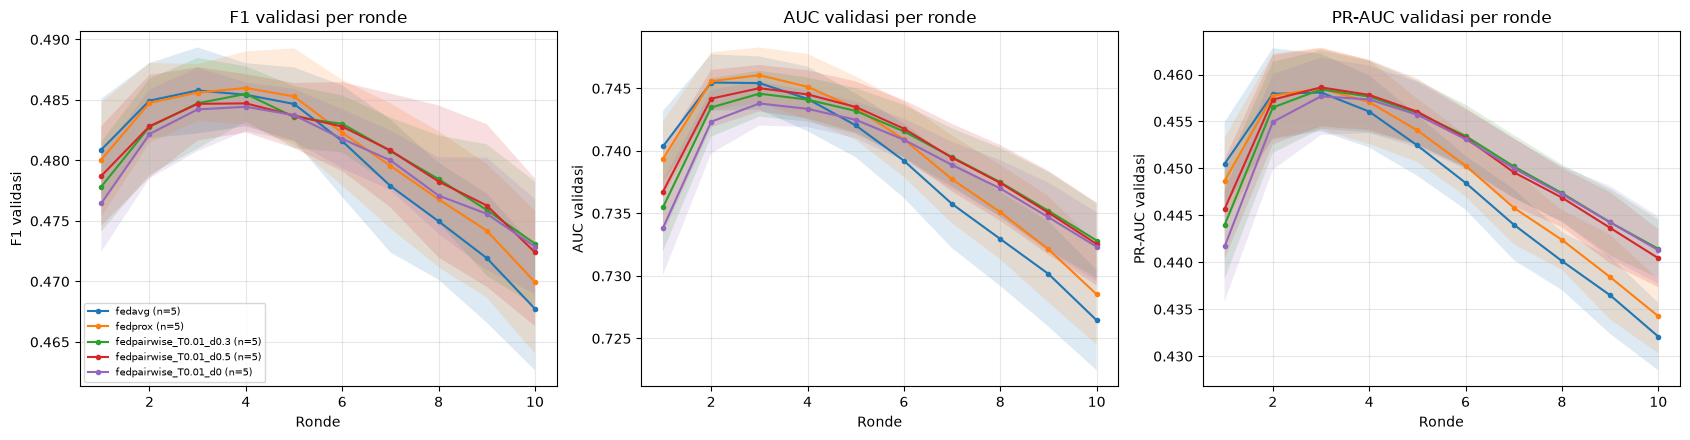

Grafik disimpan: C:\Users\s2\Documents\FIXRKI\FIXbanget\baselinefed\withoutEarlystopingTop20NewScenario\top20\kurva_roc_pr_test.png


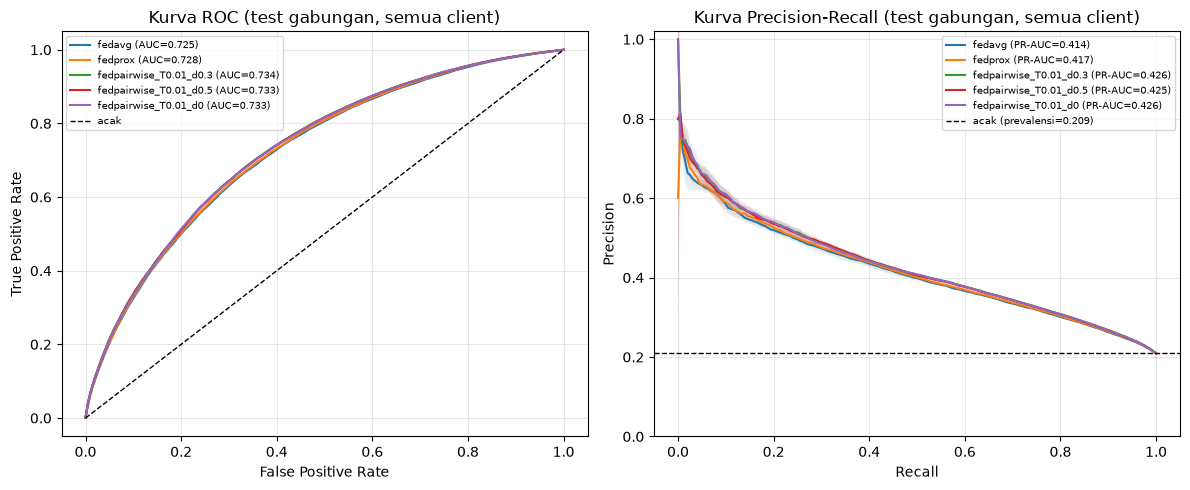

In [4]:
# ============================================================
# 3. KOMPARASI
# ============================================================
def collect_result(secs):
    model = load_global_model()
    res = fl.full_report(model, splits=('val', 'test'), save=True, verbose=False)
    te, va = res['test'], res['val']
    ronde = pd.read_csv(config.OUT_DIR / 'ronde_log.csv')
    bw, _ = fl.bandwidth_report(verbose=False)
    diag = diagnostic_metrics(model, 'test')
 
    # --- log validasi per ronde (client training; aman bila kosong / semua NaN) ---
    ronde = ronde.reset_index(drop=True)
    f1 = ronde['f1'].astype(float)
    val_akhir = float(f1.iloc[-1]) if len(f1) else float('nan')
    if f1.notna().any():
        best = f1.idxmax()
        val_best = float(f1[best])
        best_round = int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1
 
    # --- PR-AUC trapesium (selain AP) ---
    rec, prec = diag['pr']
    pr_trapz = float(sk_auc(rec, prec)) if len(rec) > 1 else float('nan')
 
    row = {}
    for k in METRIK:
        row[k] = float(te['pooled'][k])                 # test pooled (semua client)
        row[f'val_{k}'] = float(va['pooled'][k])        # val pooled (semua client)
    row['auc'] = diag['auc']                            # konsisten dgn diagnostic
    row['prauc'] = diag['ap']
    row.update({
        'prauc_trapz':        pr_trapz,
        'prevalensi':         diag['prevalensi'],
        'f1_macro_klien':     float(te['per_client']['f1'].mean()),
        'f1_std_klien':       float(te['per_client']['f1'].std()),
        'val_f1_macro_klien': float(va['per_client']['f1'].mean()),
        'val_f1_akhir':       val_akhir,        # F1 val berbobot ronde terakhir (client latih)
        'val_f1_terbaik':     val_best,
        'ronde_terbaik':      best_round,
        'n_client_eval':      len(te['per_client']),
        'total_MB':           float(bw['total_MB']),
        'waktu_s':            round(secs, 1),
    })
    # hasil test per grup: client ikut latih vs tidak ikut latih
    for grp in ('latih', 'non_latih'):
        for m in ('f1', 'auc', 'prauc'):
            row[f'{m}_{grp}'] = float(te['pooled_group'][grp][m])
 
    per_client = {'test': te['per_client'], 'val': va['per_client']}
    return row, per_client, ronde, diag
 
 
def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"
 
 
def summarize_seeds(per_seed):
    """Mean & std antar seed untuk semua kolom -> DataFrame numerik."""
    cols = [c for c in ALL_COLS if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')
 
    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    return num.sort_values('f1_mean', ascending=False)
 
 
def format_table(num, cols):
    """Tabel teks 'mean ± std' untuk sebagian kolom."""
    cols = [c for c in cols if f'{c}_mean' in num.columns]
    t = pd.DataFrame(index=num.index)
    t['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s', 'n_client_eval') else 4
        t[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                     int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return t
 
 
def _pvalue(d):
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)
 
 
def paired_vs_baseline(per_seed, baseline, metrics=PAIRED_METRICS):
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None
 
 
def _get_plt():
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        return plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return None
 
 
def _finish(plt, fig, out_path):
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)
 
 
def plot_curves(kurva, out_path):
    """F1, AUC & PR-AUC validasi per ronde (client training): rata-rata antar seed, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)
 
    panels = [('f1', 'F1 validasi'), ('auc', 'AUC validasi'),
              ('prauc', 'PR-AUC validasi')]
    fig, axes = plt.subplots(1, len(panels), figsize=(17, 4.5))
    for ax, (col, judul) in zip(axes, panels):
        for algo, rs in per_algo.items():
            rs = [r for r in rs if col in r.columns]
            if not rs:
                continue
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values,
                                alpha=0.15)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde')
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=7)
    _finish(plt, fig, out_path)
 
 
def plot_roc_pr(diags, out_path):
    """Kurva ROC & PR test gabungan (semua client): rata-rata antar seed, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), d in diags.items():
        per_algo.setdefault(algo, []).append(d)
 
    grid = np.linspace(0, 1, 201)
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
 
    for algo, ds in per_algo.items():
        tprs = np.array([np.interp(grid, *d['roc']) for d in ds])
        precs = np.array([np.interp(grid, d['pr'][0][::-1], d['pr'][1][::-1])
                          for d in ds])
        auc_m = np.nanmean([d['auc'] for d in ds])
        ap_m = np.nanmean([d['ap'] for d in ds])
 
        mu = tprs.mean(0)
        ax_roc.plot(grid, mu, label=f'{algo} (AUC={auc_m:.3f})')
        mu_p = precs.mean(0)
        ax_pr.plot(grid, mu_p, label=f'{algo} (PR-AUC={ap_m:.3f})')
        if len(ds) > 1:
            sd = tprs.std(0, ddof=1)
            ax_roc.fill_between(grid, mu - sd, mu + sd, alpha=0.12)
            sd_p = precs.std(0, ddof=1)
            ax_pr.fill_between(grid, mu_p - sd_p, mu_p + sd_p, alpha=0.12)
 
    prev = np.mean([d['prevalensi'] for ds in per_algo.values() for d in ds])
    ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='acak')
    ax_pr.axhline(prev, color='k', ls='--', lw=1,
                  label=f'acak (prevalensi={prev:.3f})')
 
    ax_roc.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
               title='Kurva ROC (test gabungan, semua client)')
    ax_pr.set(xlabel='Recall', ylabel='Precision',
              title='Kurva Precision-Recall (test gabungan, semua client)',
              ylim=(0, 1.02))
    for ax in (ax_roc, ax_pr):
        ax.grid(alpha=0.3)
        ax.legend(loc='best', fontsize=7)
    _finish(plt, fig, out_path)
 
 
def per_client_tables(per_client, algos):
    """{(split, metrik): DataFrame state x algoritma, rata-rata antar seed}.
    Ditambah baris makro: semua / client latih / client non-latih."""
    latih = list(fl.state_list())
    tabel = {}
    for split in ('val', 'test'):
        for met in METRIK:
            t = pd.DataFrame({
                algo: pd.concat([per_client[k][split][met]
                                 for k in per_client if k[0] == algo],
                                axis=1).mean(axis=1)
                for algo in algos})
            ada_latih = [s for s in latih if s in t.index]
            ada_non = [s for s in t.index if s not in latih]
            t.loc['MAKRO (semua)'] = t.mean()
            if ada_latih:
                t.loc['MAKRO (latih)'] = t.loc[ada_latih].mean()
            if ada_non:
                t.loc['MAKRO (non-latih)'] = t.loc[ada_non].mean()
            tabel[(split, met)] = t
    return tabel
 
 
def run_compare(algos, seeds, n_clients, out_root):
    rows, per_client, kurva, diags = {}, {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} algoritma x {len(seeds)} seed = {total_run} run")
    print(f"Algoritma: {algos}")
    print(f"Seed: {seeds}")
    print(f"Log detail: {LOG_FLWR} | {LOG_PRINTS}")
 
    try:
        for seed in seeds:
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, pc, ronde, diag = collect_result(time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], per_client[key] = row, pc
                kurva[key], diags[key] = ronde, diag
                print(f"[selesai] {algo} s{seed}: "
                      f"VAL F1 {row['val_f1']:.4f} AP {row['val_prauc']:.4f} | "
                      f"TEST F1 {row['f1']:.4f} AUC {row['auc']:.4f} "
                      f"PR-AUC {row['prauc']:.4f} | "
                      f"{row['total_MB']:.2f} MB | {row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED
 
    if not rows:
        sys.exit("Tidak ada run yang berhasil.")
 
    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)
 
    num = summarize_seeds(per_seed)
    berpasangan = paired_vs_baseline(per_seed, BASELINE)
    tabel_klien = per_client_tables(per_client, list(num.index))
 
    n_eval = int(per_seed['n_client_eval'].iloc[0])
    print("\n" + "=" * 70)
    print(f"PERBANDINGAN AGREGASI - TEST (pooled {n_eval} client; "
          f"rata-rata ± std antar seed; urut F1)")
    print("=" * 70)
    print(format_table(num, TEST_COLS).to_string())
 
    print("\n" + "=" * 70)
    print(f"PERBANDINGAN AGREGASI - VALIDASI (model akhir, pooled {n_eval} client)")
    print("=" * 70)
    print(format_table(num, VAL_COLS).to_string())
 
    print("\n" + "=" * 70)
    print("TEST per grup (pooled): client IKUT latih vs TIDAK ikut latih")
    print("=" * 70)
    print(format_table(num, GRUP_COLS).to_string())
 
    print("\n" + "=" * 70)
    print("LAINNYA (F1 antar client, val per ronde, bandwidth, waktu)")
    print("=" * 70)
    print(format_table(num, EXTRA_COLS).to_string())
 
    print("\nHasil per seed (VAL | TEST):")
    for split, pref in (('VAL', 'val_'), ('TEST', '')):
        cols = [f'{pref}f1', f'{pref}auc', f'{pref}prauc']
        print(f"\n[{split}] F1 | AUC | PR-AUC")
        print(per_seed[cols].round(4).unstack('seed').to_string())
 
    if berpasangan is not None:
        print(f"\nSelisih TEST terhadap {BASELINE} pada seed yang sama "
              f"(positif = lebih baik dari {BASELINE}):")
        print(berpasangan.round(4).to_string())
        if int(berpasangan['n_seed'].min()) < 5:
            print("Catatan: dengan <5 seed uji-t lemah; lihat kolom *_menang dan "
                  "konsistensi arah selisih.")
    elif len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/gagal.")
 
    for split in ('val', 'test'):
        for met in ('f1', 'prauc'):
            print(f"\n{met.upper()} {split.upper()} per state (rata-rata antar seed):")
            print(tabel_klien[(split, met)].round(4).to_string())
 
    print(f"\nTerbaik F1 test (rata-rata)     : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC test (rata-rata)    : {num['auc_mean'].idxmax()}")
    print(f"Terbaik PR-AUC test (rata-rata) : {num['prauc_mean'].idxmax()}")
    print(f"Terbaik F1 val (rata-rata)      : {num['val_f1_mean'].idxmax()}")
    print(f"Terbaik PR-AUC val (rata-rata)  : {num['val_prauc_mean'].idxmax()}")
    if 'f1_non_latih_mean' in num.columns and num['f1_non_latih_mean'].notna().any():
        print(f"Terbaik F1 client non-latih     : {num['f1_non_latih_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed        : {num['f1_std'].idxmin()} "
              f"(std F1 test terkecil)")
    print(f"Paling merata antar state       : {num['f1_std_klien_mean'].idxmin()}")
    mb = num['total_MB_mean']
    if (mb.max() - mb.min()) > 0.01 * mb.max():
        print(f"Bandwidth terkecil              : {mb.idxmin()}")
    else:
        print("Bandwidth                       : sama untuk semua algoritma")
 
    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan.csv')
    for (split, met), t in tabel_klien.items():
        t.to_csv(out_root / f'perbandingan_{split}_{met}_per_client.csv')
    if berpasangan is not None:
        berpasangan.to_csv(out_root / 'perbandingan_berpasangan.csv')
    print(f"\nCSV disimpan di: {out_root}")
    plot_curves(kurva, out_root / 'kurva_validasi.png')
    plot_roc_pr(diags, out_root / 'kurva_roc_pr_test.png')
    return per_seed, num
 
 
# %%
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description="Simulasi Federated Learning")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu algoritma saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar algoritma untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4 (opsional)")
    ap.add_argument('--top10', action='store_true',
                    help="training hanya pakai 10 state (TOP10_STATES)")
    ap.add_argument('--top20', action='store_true',
                    help="training hanya pakai 20 state (TOP20_STATES)")
    ap.add_argument('--states', nargs='+', type=int, default=None,
                    help="training pakai daftar state sendiri, mis. --states 5 10 13")
    ap.add_argument('--all', action='store_true',
                    help="training pakai semua state (menimpa DEFAULT_SET)")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    args, _ = ap.parse_known_args(argv)
 
    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
    # prioritas: --states > --all > --top10 > --top20 > DEFAULT_SET
    if args.states:
        states, set_name = args.states, f'custom{len(args.states)}'
    elif args.all:
        states, set_name = None, ''
    elif args.top10:
        states, set_name = TOP10_STATES, 'top10'
    elif args.top20:
        states, set_name = TOP20_STATES, 'top20'
    elif DEFAULT_SET:
        states, set_name = STATE_SETS[DEFAULT_SET], DEFAULT_SET
    else:
        states, set_name = None, ''
 
    show_modules()
    setup_dataset()
    apply_states(states)          # <- setelah setup_dataset (yang meng-clear cache)
    n_clients = data_summary()
    if args.info:
        return
 
    # output dipisah per set state supaya top10 / top20 / semua state tidak saling menimpa
    out_root = ORIG_OUT_DIR.parent / set_name
 
    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)
 
 
if __name__ == '__main__':
    main()